In [1]:
# ==============================
# Mount Drive
# ==============================
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
from keras.layers import Conv1D, Conv2D, MaxPooling1D, MaxPooling2D
from keras.models import Sequential
from keras.layers import Activation, Flatten, Dense, Dropout, LSTM, Concatenate, Input, Bidirectional, RepeatVector, Reshape, GaussianNoise
from tensorflow.keras.optimizers import SGD, Adam, RMSprop
from tensorflow.keras import regularizers
import tensorflow as tf

from tensorflow.keras.models import Model
import random
import math
import scipy as sp
import numpy as np
import scipy.io
import cmath
from math import log
from google.colab import drive
from numpy import savetxt

################################################################################

# ── 4-SU data (sample length = 64) ───────────────────────────────────────────
Xcu_train = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcu_train64x.npy')
Xcx_train = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcx_train64x.npy')
Xcy_train = np.load( '/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcy_train64x.npy')
Xcz_train = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcz_train64x.npy')

Xcu_test  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcu_test64x.npy')
Xcx_test  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcx_test64x.npy')
Xcy_test  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcy_test64x.npy')
Xcz_test  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcz_test64x.npy')

Yc_train  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_train64x.npy')
Yc_test   = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_val64x.npy')

# ── 3-SU benchmark data (sample length = 15) ─────────────────────────────────
Xcx_trainx = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcx_train15x.npy')
Xcy_trainx = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcy_train15x.npy')
Xcz_trainx = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcz_train15x.npy')

Xcx_testx  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcx_test15x.npy')
Xcy_testx  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcy_test15x.npy')
Xcz_testx  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcz_test15x.npy')

Yc_trainx  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_train15x.npy')
Yc_testx   = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_val15x.npy')

print("✅ Data loaded successfully!")
print(f"   Xcu_train shape : {Xcu_train.shape}")
print(f"   Yc_train  shape : {Yc_train.shape}")

✅ Data loaded successfully!
   Xcu_train shape : (117000, 256, 1)
   Yc_train  shape : (117000, 2)


In [3]:
###### Creating CNN model ######################################################
################################################################################
################################################################################
L2 = 0.001
N = 64
M = 4
towers = []
inp_u = Input(shape=(N*M,1))
inp_x = Input(shape=(N*M,1))
inp_y = Input(shape=(N*M,1))
inp_z = Input(shape=(N*M,1))
#
c1 = Conv1D(40, 9, padding='same', strides=1)(inp_u)
c1_activation = Activation('relu')(c1)
conv_2 = Conv1D(40, 9, padding='same', strides=1)(c1_activation)
conv_2_activation = Activation('relu')(conv_2)
max = MaxPooling1D(pool_size=2)(conv_2_activation)
fc_1_drop = Flatten()(max)
fc_1_drop = Dropout(0.1)(fc_1_drop)
fc_1_reshape = RepeatVector(1)(fc_1_drop)
out_cnn = Dense(128, kernel_regularizer=regularizers.l2(L2), activity_regularizer=regularizers.l2(L2))(fc_1_drop)
towers.append(out_cnn)
u = Model(inputs=inp_u, outputs=out_cnn)
#
c1 = Conv1D(40, 9, padding='same', strides=1)(inp_x)
c1_activation = Activation('relu')(c1)
conv_2 = Conv1D(40, 9, padding='same', strides=1)(c1_activation)
conv_2_activation = Activation('relu')(conv_2)
max = MaxPooling1D(pool_size=2)(conv_2_activation)
fc_1_drop = Flatten()(max)
fc_1_drop = Dropout(0.1)(fc_1_drop)
fc_1_reshape = RepeatVector(1)(fc_1_drop)
out_cnn = Dense(128, kernel_regularizer=regularizers.l2(L2), activity_regularizer=regularizers.l2(L2))(fc_1_drop)
towers.append(out_cnn)
x = Model(inputs=inp_x, outputs=out_cnn)
#
c1 = Conv1D(40, 9, padding='same', strides=1)(inp_y)
c1_activation = Activation('relu')(c1)
conv_2 = Conv1D(40, 9, padding='same', strides=1)(c1_activation)
conv_2_activation = Activation('relu')(conv_2)
max = MaxPooling1D(pool_size=2)(conv_2_activation)
fc_1_drop = Flatten()(max)
fc_1_drop = Dropout(0.1)(fc_1_drop)
fc_1_reshape = RepeatVector(1)(fc_1_drop)
out_cnn = Dense(128, kernel_regularizer=regularizers.l2(L2), activity_regularizer=regularizers.l2(L2))(fc_1_drop)
towers.append(out_cnn)
y = Model(inputs=inp_y, outputs=out_cnn)
#
c1 = Conv1D(40, 9, padding='same', strides=1)(inp_z)
c1_activation = Activation('relu')(c1)
conv_2 = Conv1D(40, 9, padding='same', strides=1)(c1_activation)
conv_2_activation = Activation('relu')(conv_2)
max = MaxPooling1D(pool_size=2)(conv_2_activation)
fc_1_drop = Flatten()(max)
fc_1_drop = Dropout(0.1)(fc_1_drop)
fc_1_reshape = RepeatVector(1)(fc_1_drop)
out_cnn = Dense(128, kernel_regularizer=regularizers.l2(L2), activity_regularizer=regularizers.l2(L2))(fc_1_drop)
towers.append(out_cnn)
z = Model(inputs=inp_z, outputs=out_cnn)
out = Concatenate()(towers)
out = RepeatVector(1)(out)

d = Bidirectional(
        LSTM(
            64,
            dropout=0.1,
            return_sequences=False
        )
    )(out)

d = Dense(
        64,
        kernel_regularizer=regularizers.l2(L2),
        activity_regularizer=regularizers.l2(L2)
    )(d)

d = Dropout(0.1)(d)
d = Dense(2, activation='softmax')(d)

cnnblstm_model = Model(
    inputs=[inp_u, inp_x, inp_y, inp_z],
    outputs=d
)

cnnblstm_model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 256, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 256, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 256, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 256, 40)   │        400 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 256, 40)   │        400 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 256, 40)   │        400 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 256, 40)   │        400 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 40)   │          0 │ conv1d[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 256, 40)   │          0 │ conv1d_2[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 256, 40)   │          0 │ conv1d_4[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 256, 40)   │          0 │ conv1d_6[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 256, 40)   │     14,440 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 256, 40)   │     14,440 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 256, 40)   │     14,440 │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 256, 40)   │     14,440 │ activation_6[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 40)   │          0 │ conv1d_1[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 256, 40)   │          0 │ conv1d_3[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 256, 40)   │          0 │ conv1d_5[0][0]    │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,985,122 (11.39 MB)

 Trainable params: 2,985,122 (11.39 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
cnnblstm_model.compile(loss='categorical_crossentropy', optimizer='Adam', metrics=['accuracy'])
history_CNNL = cnnblstm_model.fit([Xcu_train, Xcx_train, Xcy_train, Xcz_train], Yc_train, batch_size=100, epochs=5, verbose=1, validation_data=([Xcu_test, Xcx_test, Xcy_test, Xcz_test], Yc_test))

Epoch 1/5
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 624s 524ms/step - accuracy: 0.7124 - loss: 1.6775 - val_accuracy: 0.8002 - val_loss: 0.8468
Epoch 2/5
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 621s 531ms/step - accuracy: 0.8051 - loss: 0.7312 - val_accuracy: 0.8095 - val_loss: 0.6199
Epoch 3/5
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 580s 495ms/step - accuracy: 0.8126 - loss: 0.5556 - val_accuracy: 0.8085 - val_loss: 0.5079
Epoch 4/5
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 606s 518ms/step - accuracy: 0.8151 - loss: 0.4634 - val_accuracy: 0.8011 - val_loss: 0.4496
Epoch 5/5
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 624s 520ms/step - accuracy: 0.8176 - loss: 0.4170 - val_accuracy: 0.8160 - val_loss: 0.3997


In [5]:
cnnblstm_model.save('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/CNN_BLSTM.h5')

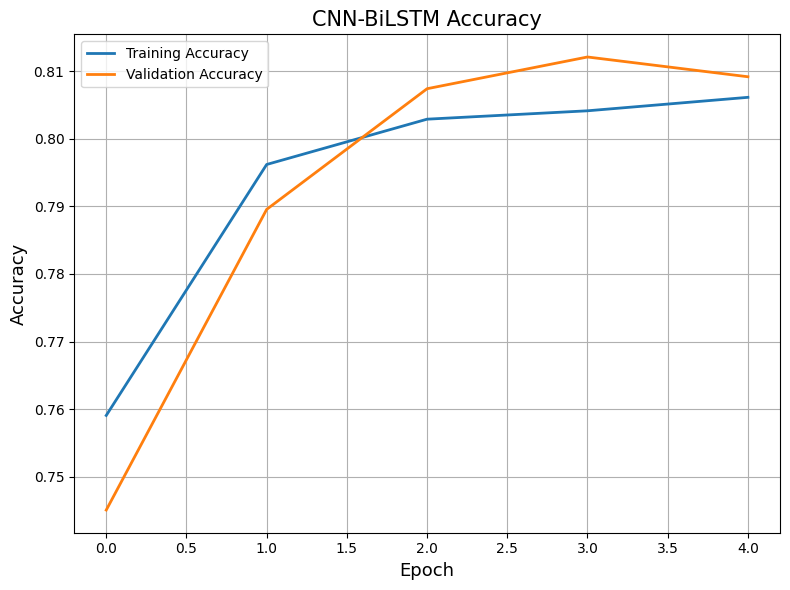

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.plot(history_CNNL.history['accuracy'],
         linewidth=2,
         label='Training Accuracy')

plt.plot(history_CNNL.history['val_accuracy'],
         linewidth=2,
         label='Validation Accuracy')

plt.xlabel('Epoch', fontsize=13)
plt.ylabel('Accuracy', fontsize=13)
plt.title('CNN-BiLSTM Accuracy', fontsize=15)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.models import load_model
import tensorflow as tf
from keras.models import load_model
from tensorflow.keras.layers import LSTM as OriginalLSTM


# Load Test Data
# ==============================
file_prefix = '/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xc'
file_suffix = '_testX.npy'
file_suffix_p = '_testP.npy'

Xc = {}
Xcp = {}

for snr in range(10,21):
    Xc[f'Xc{snr}_testX'] = np.load(file_prefix + str(snr) + file_suffix)
    Xcp[f'Xc{snr}_testP'] = np.load(file_prefix + str(snr) + file_suffix_p)

print("Files loaded successfully ✅")

Yc_test = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_testX.npy')
Yc_testP = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_testP.npy')

Files loaded successfully ✅
